# เปรียบเทียบ 15 โมเดล (Classification)
อ่านผลจาก notebook 01-15 (ต้องรันก่อน) แล้วทำ 5-fold CV และสุ่มแบ่งข้อมูลใหม่ 10 รอบ ด้วยค่าตั้งเดียวกัน (`Model/Common/model_zoo.py`)

Threshold: แต่ละโมเดลเลือกของตัวเองจาก validation ด้วย F1.5 (ให้ recall สำคัญกว่า precision 1.5 เท่า) แก้ได้ที่ `FLAG_RULE` ใน `Model/Common/evaluation_classification.py`

ผลลัพธ์: `Results/Classification/18_Model_Comparison/`

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Model", "Common")))

import numpy as np
import pandas as pd
from project import SEED, Outputs, classification_data
from metrics_classification import roc_auc
import time
import matplotlib.pyplot as plt
import plots
from evaluation_classification import (
    BETTER,
    COLORS,
    FLAG_RULE,
    TOPK,
    choose_threshold,
    fit_model,
    stratified_folds,
    topk_table,
)
from metrics_classification import (
    average_precision,
    confusion_matrix,
    precision,
    precision_recall_curve_scratch,
    recall,
    roc_curve_scratch,
)
from model_zoo import classification_models
from project import ROOT, load_json, train_val_test_split_scratch

out = Outputs("Classification", "18_Model_Comparison")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

FOLDERS = {
    "Logistic Regression": "01_Logistic_Regression",
    "Decision Tree": "02_Decision_Tree",
    "Random Forest": "03_Random_Forest",
    "Gradient Boosting": "04_Gradient_Boosting",
    "XGBoost": "05_XGBoost",
    "SVC (linear)": "06_SVC_Linear",
    "SVC (rbf)": "07_SVC_RBF",
    "k-NN": "08_KNN",
    "Naive Bayes": "09_Naive_Bayes",
    "Perceptron (averaged)": "10_Perceptron",
    "Single-Layer Perceptron": "11_Single_Layer_Perceptron",
    "MLP": "12_MLP",
    "EBM (additive)": "13_EBM",
    "Stacking (5 bases)": "14_Stacking",
    BETTER: "15_Blend_EBM_MLP",
}
res = lambda name, f: os.path.join(ROOT, "Results", "Classification", FOLDERS[name], f)
bench = pd.concat([pd.read_csv(res(n, "metrics.csv")) for n in FOLDERS]).set_index("Model")
pred = {n: np.load(res(n, "predictions.npz")) for n in FOLDERS}
p_va = {n: pred[n]["p_va"] for n in FOLDERS}
p_te = {n: pred[n]["p_te"] for n in FOLDERS}
y_va, y_te = d.y_va, d.y_te
blend = load_json("Classification", FOLDERS[BETTER], "chosen_settings.json")
models = classification_models(**blend)
print(f"{len(bench)} models loaded | blend settings from notebook 15: {blend}")

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters
15 models loaded | blend settings from notebook 15: {'ebm_weight': 0.2, 'n_mlps': 5}


## Loss (train / validation / test)

log loss (lower is better). On 16% positives a model that always answers the base rate scores a misleadingly
low log loss, so judge the models on ROC-AUC / PR-AUC / recall instead.
                              Train log loss  Validation log loss  Test log loss
Model                                                                           
Logistic Regression                   0.4620               0.4564         0.4590
Decision Tree                         0.4429               0.5012         0.5198
Random Forest                         0.3916               0.4506         0.4468
Gradient Boosting                     0.4357               0.4596         0.4590
XGBoost                               0.4174               0.4587         0.4561
SVC (linear)                          0.4136               0.4087         0.4068
SVC (rbf)                             0.3875               0.4252         0.4191
k-NN                                  0.4063               0.4269         0.4294
Naive Bay

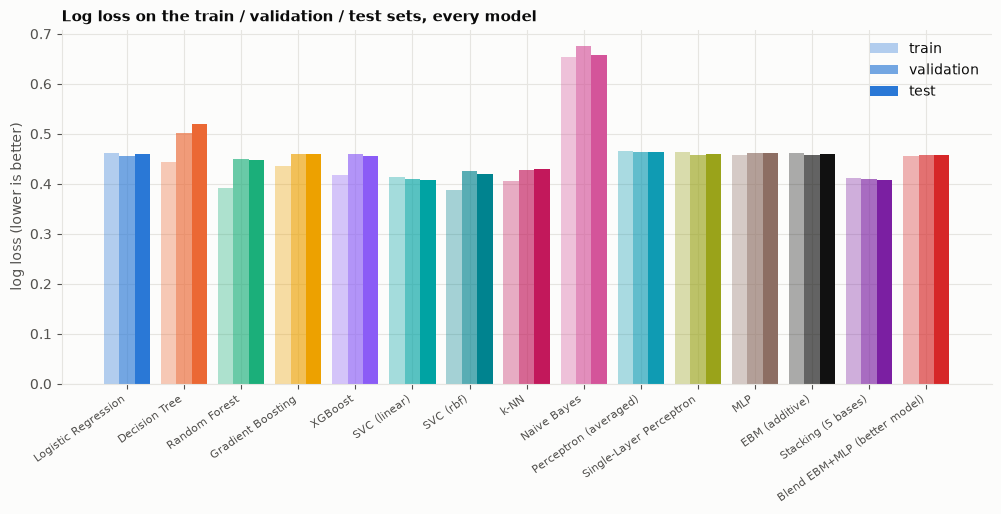

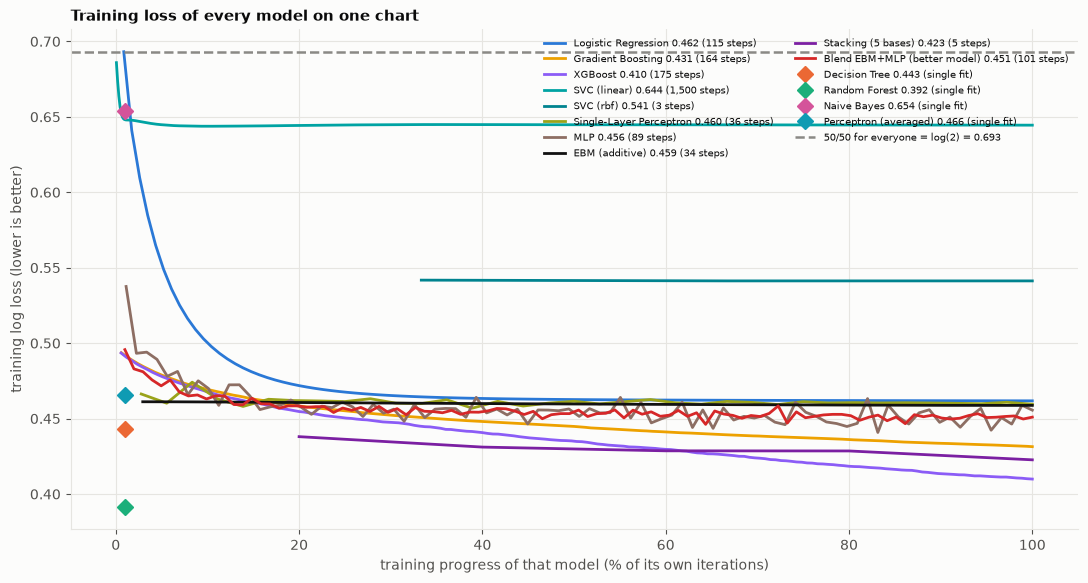

In [2]:
loss_table = bench[["train_logloss", "val_logloss", "test_logloss"]].rename(
    columns={"train_logloss": "Train log loss", "val_logloss": "Validation log loss", "test_logloss": "Test log loss"}
)
loss_table.to_csv(out.table("loss_table.csv"))
print("log loss (lower is better). On 16% positives a model that always answers the base rate scores a misleadingly")
print("low log loss, so judge the models on ROC-AUC / PR-AUC / recall instead.")
print(loss_table.to_string(float_format=lambda x: f"{x:.4f}"))

fig, ax = plt.subplots(figsize=(12, 4.6))
x, w = np.arange(len(loss_table)), 0.27
for k, (col, alpha, lab) in enumerate(
    [("Train log loss", 0.35, "train"), ("Validation log loss", 0.65, "validation"), ("Test log loss", 1.0, "test")]
):
    ax.bar(x + (k - 1) * w, loss_table[col], w, label=lab, color=[COLORS[n] for n in loss_table.index], alpha=alpha)
ax.set_xticks(x, loss_table.index, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("log loss (lower is better)")
ax.set_title("Log loss on the train / validation / test sets, every model")
ax.legend()
plots._save(fig, out.image("train_vs_test_loss.png"))

histories = {
    n: pd.read_csv(res(n, "loss_curve.csv"))["train_logloss"].values
    for n in FOLDERS
    if os.path.exists(res(n, "loss_curve.csv")) and n != "k-NN"
}
flat = [n for n in FOLDERS if n not in histories and n != "k-NN"]
fig, ax = plt.subplots(figsize=(13, 6.5))
for n, h in histories.items():
    ax.plot(
        np.arange(1, len(h) + 1) / len(h) * 100,
        h,
        color=COLORS[n],
        linewidth=2,
        label=f"{n} {h[-1]:.3f} ({len(h):,} steps)",
    )
for n in flat:
    ax.plot(
        [1],
        [loss_table.loc[n, "Train log loss"]],
        "D",
        color=COLORS[n],
        markersize=8,
        label=f"{n} {loss_table.loc[n, 'Train log loss']:.3f} (single fit)",
    )
ax.axhline(np.log(2), color=plots.NEUTRAL, linestyle="--", label="50/50 for everyone = log(2) = 0.693")
ax.set_xlabel("training progress of that model (% of its own iterations)")
ax.set_ylabel("training log loss (lower is better)")
ax.set_title("Training loss of every model on one chart")
ax.legend(fontsize=7.5, ncol=2, loc="upper right")
plots._save(fig, out.image("loss_curves_all_models.png"))

## จับคนผิดนัด: เทียบวิธีเลือก threshold และ top-x%

rule in use: f1.5 | flagged = share of the 1916 test applicants sent for review | enrichment = how much more likely a flagged applicant defaults than a random one
                              threshold  recall  precision  flagged  enrichment  recall@F1  recall@0.5  missed
Model                                                                                                         
Logistic Regression               0.221   0.862      0.206    0.667       1.293      0.449       0.197      42
Decision Tree                     0.157   0.908      0.174    0.830       1.094      0.623       0.216      28
Random Forest                     0.235   0.836      0.213    0.625       1.337      0.662       0.075      50
Gradient Boosting                 0.266   0.816      0.223    0.584       1.399      0.731       0.138      56
XGBoost                           0.262   0.744      0.222    0.533       1.397      0.744       0.161      78
SVC (linear)                      0.100   0.889      0.195  

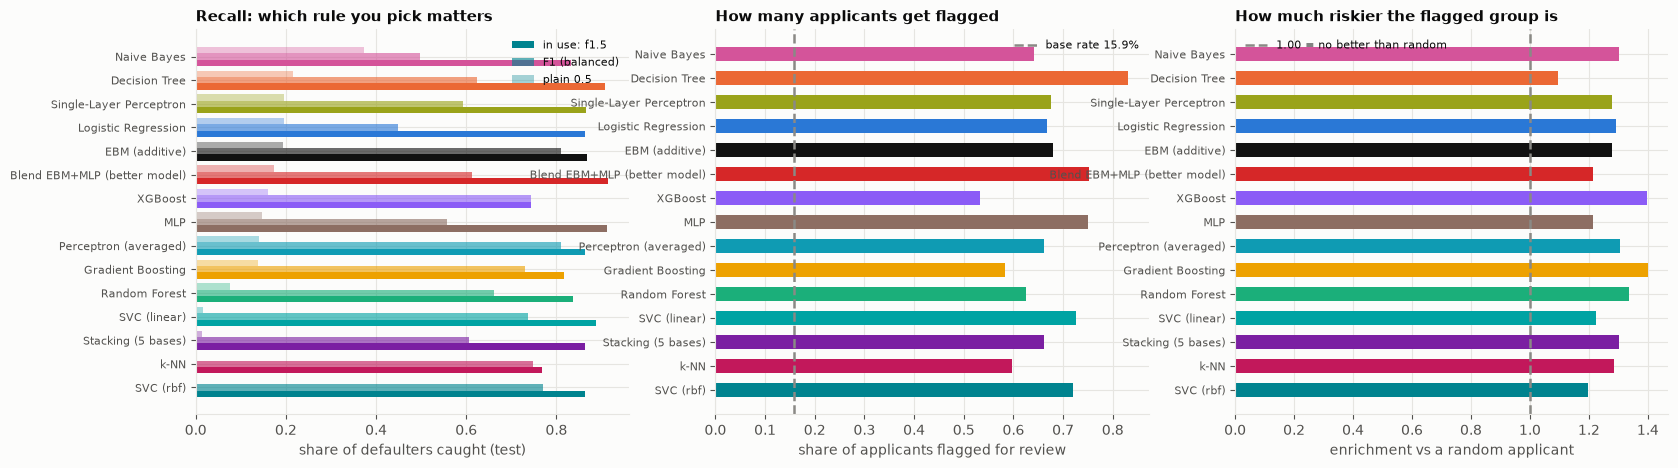


share of ALL defaulters caught if the riskiest x% of applicants is reviewed first (%):
                              top 5%  top 10%  top 20%  top 30%  top 40%  top 50%
Model                                                                            
Logistic Regression             12.5     21.3     40.3     55.4     68.2     75.4
Decision Tree                    8.9     19.3     31.8     45.6     57.7     66.9
Random Forest                   10.8     22.6     36.7     48.2     63.6     73.8
Gradient Boosting               11.1     19.3     38.0     51.1     63.6     74.1
XGBoost                         10.2     21.6     38.7     51.5     61.0     72.5
SVC (linear)                    12.1     23.0     39.0     50.8     66.6     75.7
SVC (rbf)                       11.1     19.7     36.7     50.2     58.7     68.5
k-NN                            10.8     21.0     35.1     46.6     55.7     66.9
Naive Bayes                     10.8     21.0     33.8     48.2     59.7     70.8
Perceptron

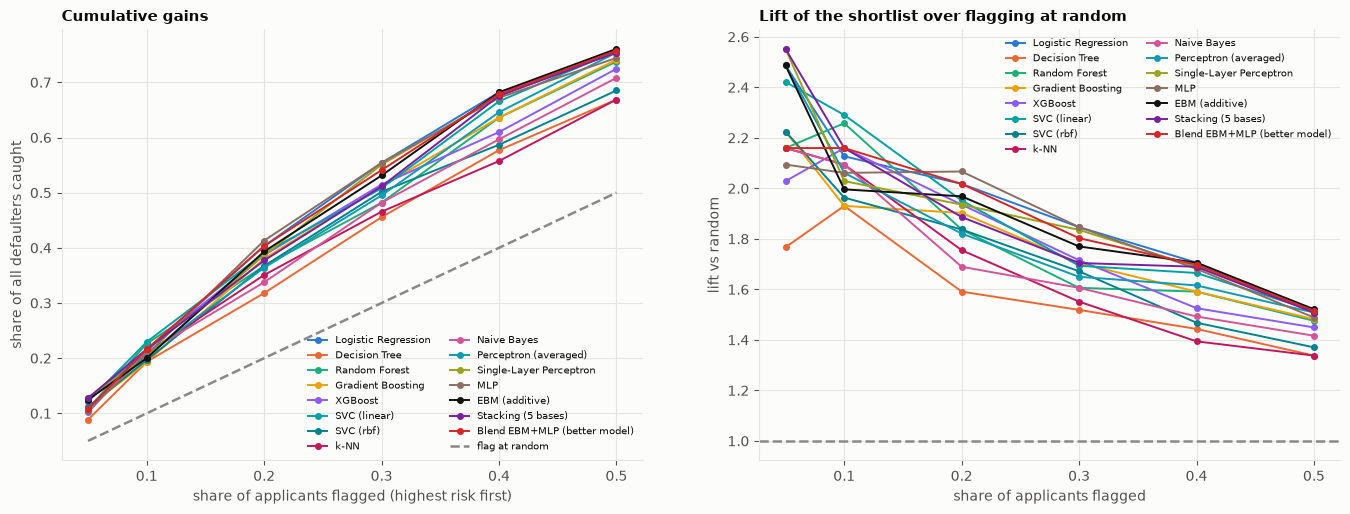

In [3]:
LADDER = ["0.5 (plain)", "f1", "f1.5", "f2", "youden", "precision>=1.5x base"]
ladder = {r: {"recall": [], "precision": [], "flagged": []} for r in LADDER}
rule_rows = []
for n in FOLDERS:
    thr = float(bench.loc[n, "chosen_threshold"])
    rule_rows.append(
        {
            "Model": n,
            "threshold": thr,
            "recall": bench.loc[n, "test_recall"],
            "precision": bench.loc[n, "test_precision"],
            "flagged": float((p_te[n] >= thr).mean()),
            "enrichment": bench.loc[n, "test_precision"] / y_te.mean(),
            "recall@F1": bench.loc[n, "test_recall@f1_rule"],
            "recall@0.5": bench.loc[n, "test_recall@0.5"],
            "missed": bench.loc[n, "test_fn"],
        }
    )
    for r in LADDER:
        t = 0.5 if r.startswith("0.5") else choose_threshold(y_va, p_va[n], rule=r, base_rate=float(y_va.mean()))[0]
        ladder[r]["recall"].append(recall(y_te, p_te[n], t))
        ladder[r]["precision"].append(precision(y_te, p_te[n], t))
        ladder[r]["flagged"].append(float((p_te[n] >= t).mean()))
rules = pd.DataFrame(rule_rows).set_index("Model")
rules.to_csv(out.table("threshold_rules.csv"))
print(
    f"rule in use: {FLAG_RULE} | flagged = share of the {len(y_te)} test applicants sent for review | "
    "enrichment = how much more likely a flagged applicant defaults than a random one"
)
print(rules.to_string(float_format=lambda x: f"{x:.3f}"))

ladder_tbl = pd.DataFrame(
    {
        r: {
            "recall (defaulters caught)": np.mean(v["recall"]),
            "precision": np.mean(v["precision"]),
            "applicants flagged": np.mean(v["flagged"]),
            "enrichment vs random": np.mean(v["precision"]) / y_te.mean(),
            f"defaulters missed (of {int(y_te.sum())})": (1 - np.mean(v["recall"])) * y_te.sum(),
        }
        for r, v in ladder.items()
    }
).T
ladder_tbl.to_csv(out.table("threshold_ladder.csv"), index_label="rule")
print("\nRULE LADDER (average over the 15 models, every rule tuned on validation, measured on test):")
print(ladder_tbl.to_string(float_format=lambda x: f"{x:.3f}"))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
o = rules.index[np.argsort(rules["recall@0.5"].values)]
xr = np.arange(len(o))
for k, (col, lab) in enumerate(
    [("recall", f"in use: {FLAG_RULE}"), ("recall@F1", "F1 (balanced)"), ("recall@0.5", "plain 0.5")]
):
    axes[0].barh(
        xr + (k - 1) * 0.27,
        rules.loc[o, col],
        0.27,
        label=lab,
        color=[COLORS[n] for n in o],
        alpha=[1.0, 0.62, 0.35][k],
    )
axes[0].set_yticks(xr, o, fontsize=8)
axes[0].set_xlabel("share of defaulters caught (test)")
axes[0].set_title("Recall: which rule you pick matters")
axes[0].legend(fontsize=8)
axes[1].barh(xr, rules.loc[o, "flagged"], 0.6, color=[COLORS[n] for n in o])
axes[1].axvline(y_te.mean(), color=plots.NEUTRAL, linestyle="--", label=f"base rate {y_te.mean():.1%}")
axes[1].set_yticks(xr, o, fontsize=8)
axes[1].set_xlabel("share of applicants flagged for review")
axes[1].set_title("How many applicants get flagged")
axes[1].legend(fontsize=8)
axes[2].barh(xr, rules.loc[o, "enrichment"], 0.6, color=[COLORS[n] for n in o])
axes[2].axvline(1.0, color=plots.NEUTRAL, linestyle="--", label="1.00 = no better than random")
axes[2].set_yticks(xr, o, fontsize=8)
axes[2].set_xlabel("enrichment vs a random applicant")
axes[2].set_title("How much riskier the flagged group is")
axes[2].legend(fontsize=8)
plots._save(fig, out.image("threshold_rules.png"))

topk = pd.DataFrame([{"Model": n, **r} for n in FOLDERS for r in topk_table(y_te, p_te[n])])
topk.to_csv(out.table("recall_at_topk.csv"), index=False)
recap = (topk.pivot(index="Model", columns="flagged share", values="recall (defaulters caught / all)") * 100).reindex(
    list(FOLDERS)
)
recap.columns = [f"top {int(round(c * 100))}%" for c in recap.columns]
print("\nshare of ALL defaulters caught if the riskiest x% of applicants is reviewed first (%):")
print(recap.to_string(float_format=lambda x: f"{x:5.1f}"))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16.5, 5.6))
for n in FOLDERS:
    s = topk[topk["Model"] == n]
    a1.plot(
        s["flagged share"],
        s["recall (defaulters caught / all)"],
        "o-",
        color=COLORS[n],
        label=n,
        linewidth=1.4,
        markersize=4,
    )
    a2.plot(
        s["flagged share"], s["lift vs flagging at random"], "o-", color=COLORS[n], label=n, linewidth=1.4, markersize=4
    )
a1.plot(TOPK, TOPK, "--", color=plots.NEUTRAL, label="flag at random")
a1.set_xlabel("share of applicants flagged (highest risk first)")
a1.set_ylabel("share of all defaulters caught")
a1.set_title("Cumulative gains")
a1.legend(fontsize=7, ncol=2)
a2.axhline(1.0, color=plots.NEUTRAL, linestyle="--")
a2.set_xlabel("share of applicants flagged")
a2.set_ylabel("lift vs random")
a2.set_title("Lift of the shortlist over flagging at random")
a2.legend(fontsize=7, ncol=2)
plots._save(fig, out.image("recall_at_topk.png"))

## Confusion matrix, accuracy, precision, recall, F1, ROC-AUC (test)

                              chosen_threshold  test_accuracy  test_precision  test_recall  test_specificity   test_f1  test_roc_auc  test_pr_auc  test_fn
Model                                                                                                                                                     
Blend EBM+MLP (better model)          0.207246       0.379436        0.193481     0.914754          0.278088  0.319405      0.709538     0.297263       26
MLP                                   0.214273       0.379958        0.193190     0.911475          0.279330  0.318807      0.708933     0.296745       27
Logistic Regression                   0.220701       0.448330        0.205790     0.862295          0.369957  0.332280      0.706731     0.296645       42
EBM (additive)                        0.221063       0.437370        0.203377     0.868852          0.355680  0.329602      0.705272     0.295541       40
Single-Layer Perceptron               0.220653       0.439979        0

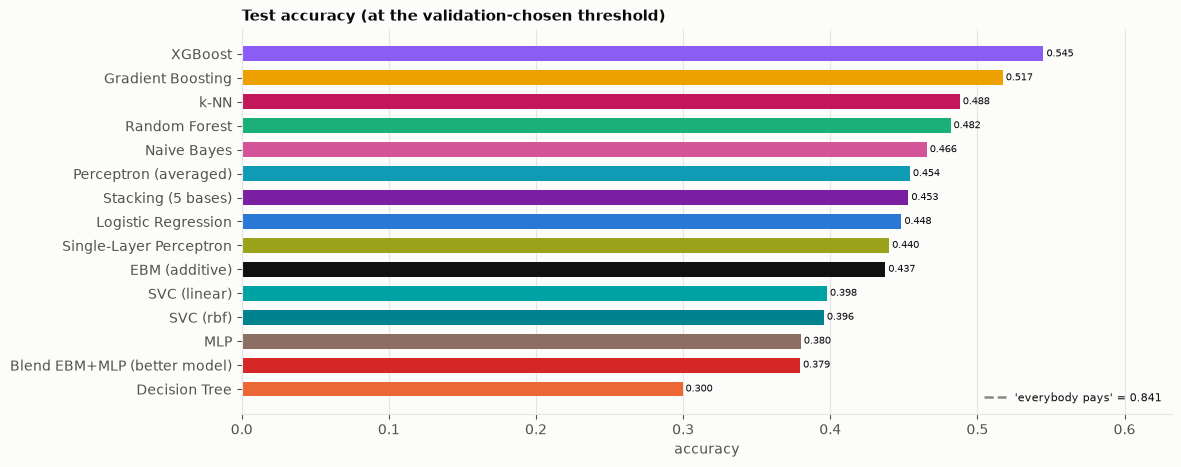

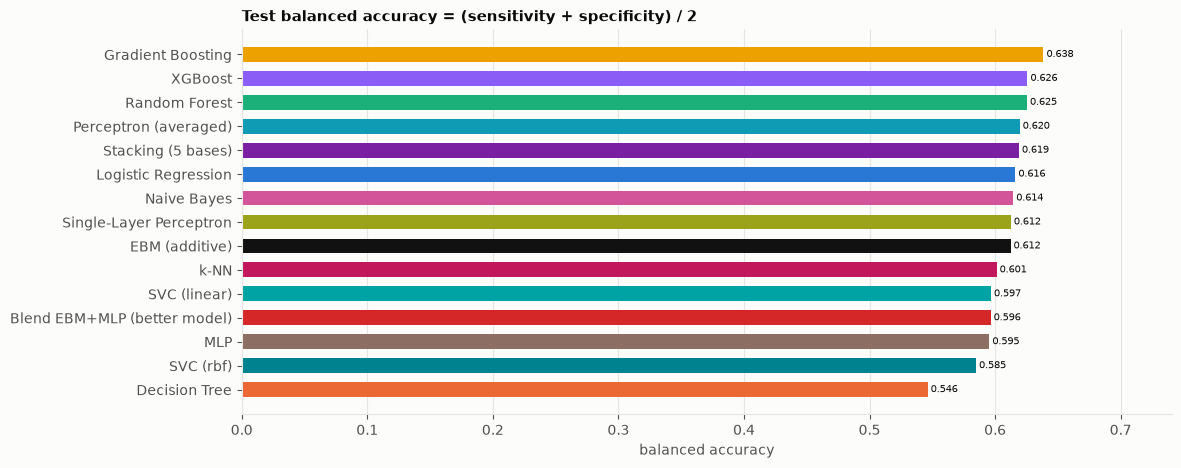

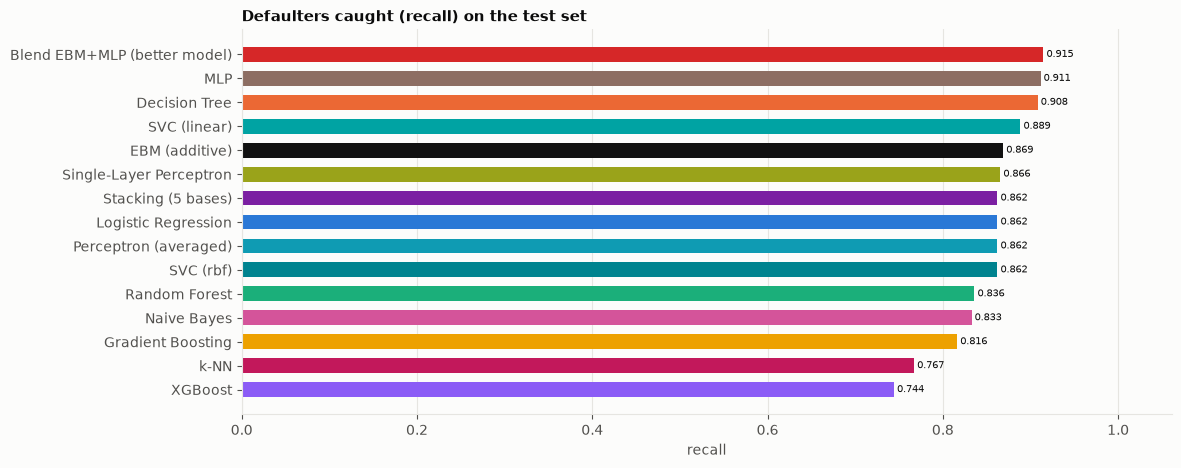

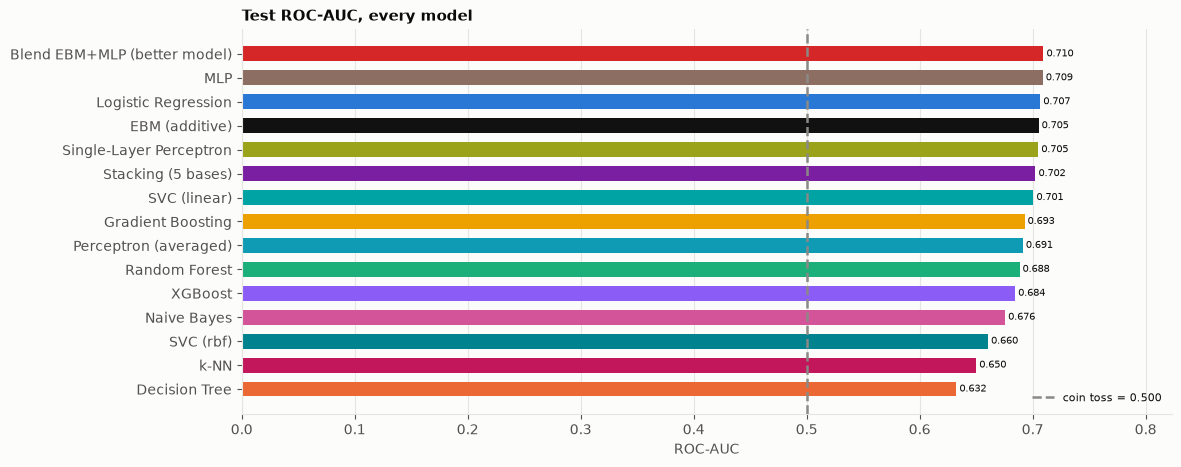

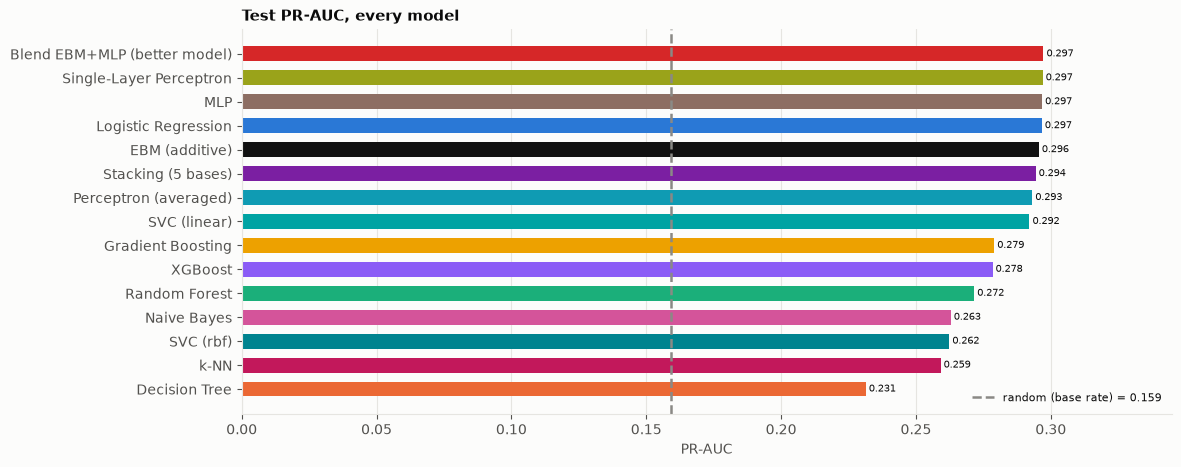

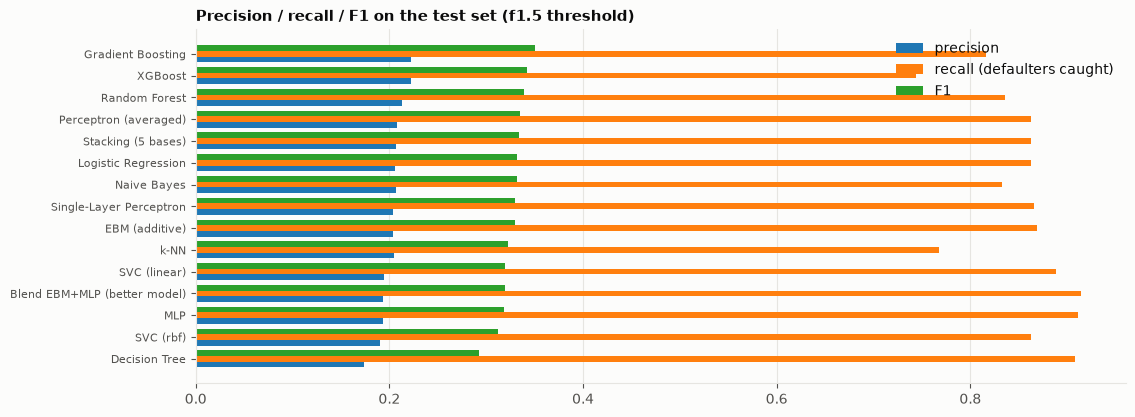

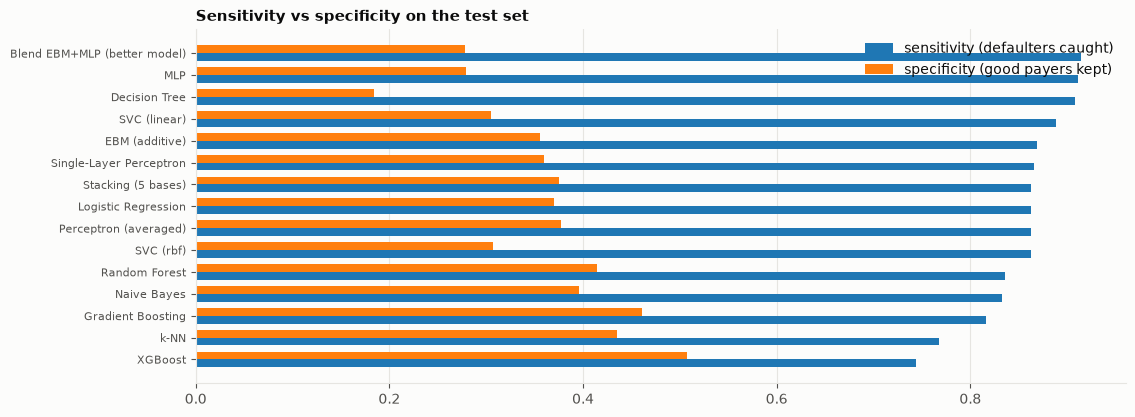

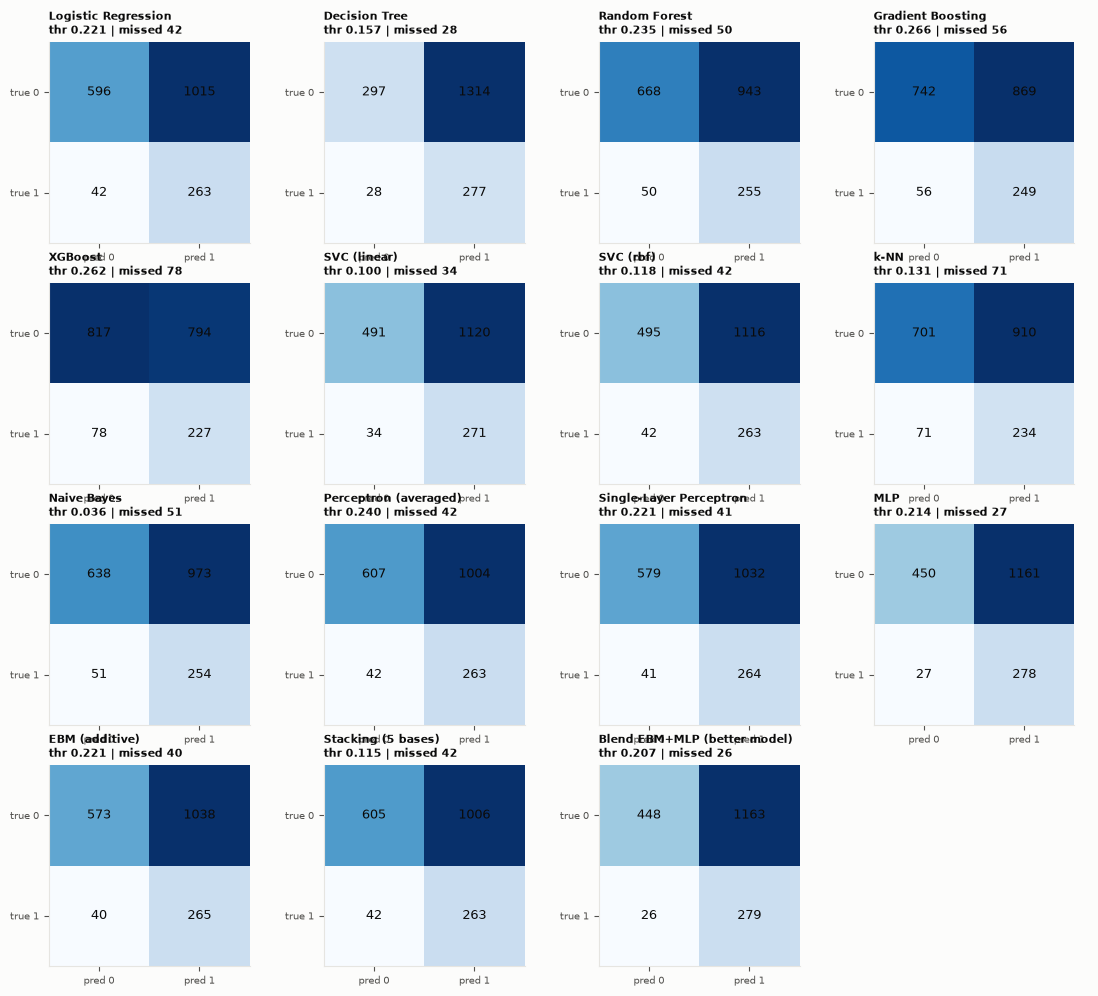

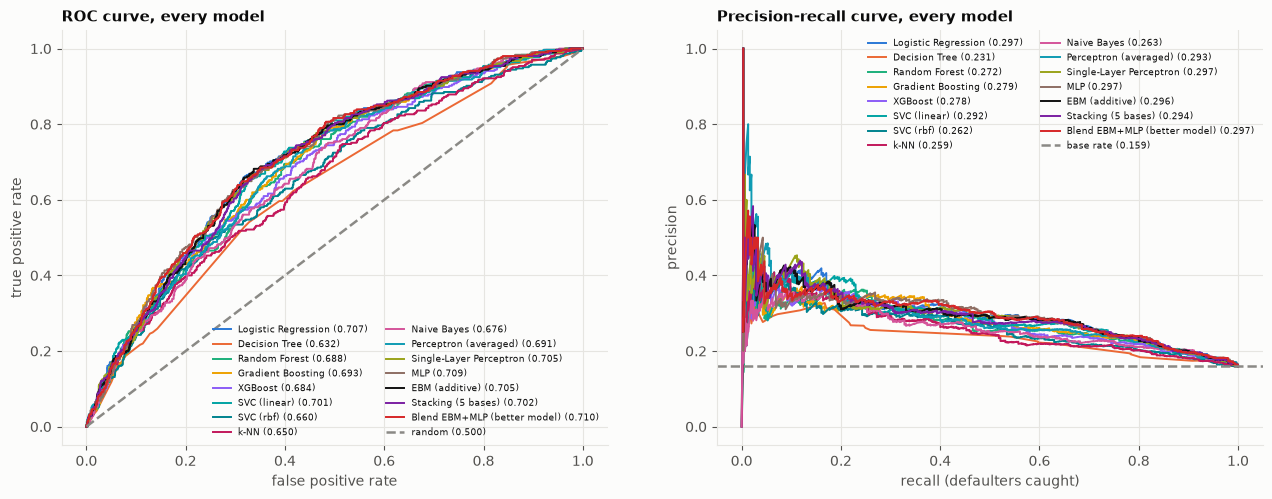

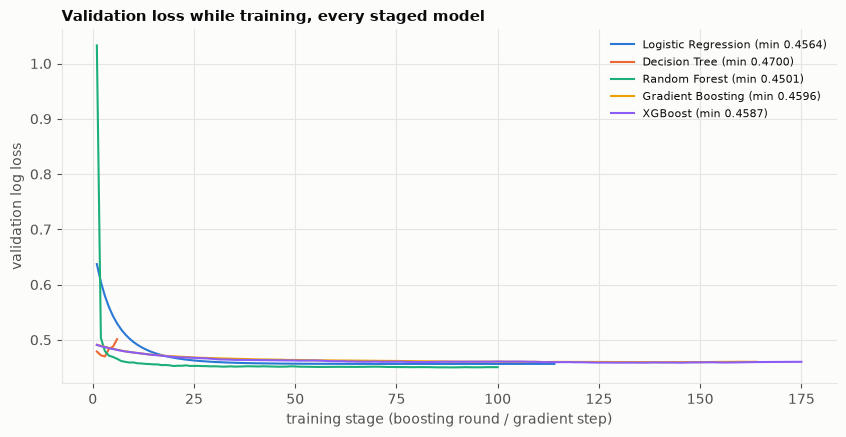

In [4]:
print(
    bench[
        [
            "chosen_threshold",
            "test_accuracy",
            "test_precision",
            "test_recall",
            "test_specificity",
            "test_f1",
            "test_roc_auc",
            "test_pr_auc",
            "test_fn",
        ]
    ]
    .sort_values("test_roc_auc", ascending=False)
    .to_string()
)
bench.to_csv(out.table("benchmark_all_metrics.csv"))

def bar(col, title, fname, xlabel, ref=None, ref_label=""):
    fig, ax = plt.subplots(figsize=(12, 5))
    order = bench[col].sort_values().index
    ax.barh(order, bench.loc[order, col], color=[COLORS[n] for n in order], height=0.62)
    if ref is not None:
        ax.axvline(ref, color=plots.NEUTRAL, linestyle="--", label=f"{ref_label} = {ref:.3f}")
        ax.legend(fontsize=8)
    for n, v in bench.loc[order, col].items():
        ax.text(v, n, f" {v:.3f}", va="center", fontsize=7)
    ax.set_xlim(0, bench[col].max() * 1.16)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    plots._save(fig, out.image(fname))

bar(
    "test_accuracy",
    "Test accuracy (at the validation-chosen threshold)",
    "accuracy.png",
    "accuracy",
    ref=1 - y_te.mean(),
    ref_label="'everybody pays'",
)
bar(
    "test_balanced_accuracy",
    "Test balanced accuracy = (sensitivity + specificity) / 2",
    "balanced_accuracy.png",
    "balanced accuracy",
)
bar("test_recall", "Defaulters caught (recall) on the test set", "recall.png", "recall")
bar("test_roc_auc", "Test ROC-AUC, every model", "roc_auc.png", "ROC-AUC", ref=0.5, ref_label="coin toss")
bar(
    "test_pr_auc",
    "Test PR-AUC, every model",
    "pr_auc.png",
    "PR-AUC",
    ref=float(y_te.mean()),
    ref_label="random (base rate)",
)

fig, ax = plt.subplots(figsize=(12, 4.6))
o = bench["test_f1"].sort_values().index
for k, (col, lab) in enumerate(
    [("test_precision", "precision"), ("test_recall", "recall (defaulters caught)"), ("test_f1", "F1")]
):
    ax.barh(np.arange(len(o)) + (k - 1) * 0.26, bench.loc[o, col], 0.26, label=lab)
ax.set_yticks(np.arange(len(o)), o, fontsize=8)
ax.legend()
ax.grid(axis="y", visible=False)
ax.set_title(f"Precision / recall / F1 on the test set ({FLAG_RULE} threshold)")
plots._save(fig, out.image("precision_recall_f1.png"))

fig, ax = plt.subplots(figsize=(12, 4.6))
o = bench["test_recall"].sort_values().index
for k, (col, lab) in enumerate(
    [("test_recall", "sensitivity (defaulters caught)"), ("test_specificity", "specificity (good payers kept)")]
):
    ax.barh(np.arange(len(o)) + (k - 0.5) * 0.36, bench.loc[o, col], 0.36, label=lab)
ax.set_yticks(np.arange(len(o)), o, fontsize=8)
ax.legend()
ax.grid(axis="y", visible=False)
ax.set_title("Sensitivity vs specificity on the test set")
plots._save(fig, out.image("sensitivity_specificity.png"))

fig, axes = plt.subplots(4, 4, figsize=(13.6, 12))
for ax in axes.ravel()[len(FOLDERS) :]:
    ax.axis("off")
for ax, n in zip(axes.ravel(), FOLDERS):
    cm = confusion_matrix(y_te, p_te[n], bench.loc[n, "chosen_threshold"])
    ax.imshow(cm, cmap="Blues")
    ax.grid(False)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha="center", va="center", fontsize=9)
    ax.set_xticks([0, 1], ["pred 0", "pred 1"], fontsize=7)
    ax.set_yticks([0, 1], ["true 0", "true 1"], fontsize=7)
    ax.set_title(f"{n}\nthr {bench.loc[n, 'chosen_threshold']:.3f} | missed {int(bench.loc[n, 'test_fn'])}", fontsize=8)
plots._save(fig, out.image("confusion_matrices.png"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15.5, 5.4))
for n in FOLDERS:
    fpr, tpr, _ = roc_curve_scratch(y_te, p_te[n])
    a1.plot(fpr, tpr, color=COLORS[n], label=f"{n} ({bench.loc[n, 'test_roc_auc']:.3f})", linewidth=1.4)
    pr, rc, _ = precision_recall_curve_scratch(y_te, p_te[n])
    a2.plot(rc, pr, color=COLORS[n], label=f"{n} ({bench.loc[n, 'test_pr_auc']:.3f})", linewidth=1.4)
a1.plot([0, 1], [0, 1], color=plots.NEUTRAL, linestyle="--", label="random (0.500)")
a1.set_xlabel("false positive rate")
a1.set_ylabel("true positive rate")
a1.set_title("ROC curve, every model")
a1.legend(fontsize=6.5, ncol=2)
a2.axhline(y_te.mean(), color=plots.NEUTRAL, linestyle="--", label=f"base rate ({y_te.mean():.3f})")
a2.set_xlabel("recall (defaulters caught)")
a2.set_ylabel("precision")
a2.set_title("Precision-recall curve, every model")
a2.legend(fontsize=6.5, ncol=2)
plots._save(fig, out.image("roc_and_pr_curves.png"))

fig, ax = plt.subplots(figsize=(10, 4.6))
for n in FOLDERS:
    if os.path.exists(res(n, "performance_curve.csv")):
        c = pd.read_csv(res(n, "performance_curve.csv"))
        ax.plot(
            c["stage"],
            c["val_logloss"],
            color=COLORS[n],
            label=f"{n} (min {c['val_logloss'].min():.4f})",
            linewidth=1.5,
        )
ax.set_xlabel("training stage (boosting round / gradient step)")
ax.set_ylabel("validation log loss")
ax.set_title("Validation loss while training, every staged model")
ax.legend(fontsize=8)
plots._save(fig, out.image("validation_curves.png"))

## โค้ดที่เขียนเอง vs scikit-learn

                                                                         AUC scratch  AUC sklearn  difference                   the difference is
check                                                                                                                                            
Logistic Regression vs sklearn LogisticRegression                             0.7067       0.7044      0.4694                         max |dcoef|
Decision Tree vs sklearn DecisionTreeClassifier (identical predictions)       0.6325       0.6351      0.1190                 1 - share identical
Random Forest vs sklearn RandomForestClassifier                               0.6884       0.6887      0.2400                            max |dP|
Gradient Boosting vs sklearn GradientBoostingClassifier                       0.6928       0.6664      0.3709                            max |dP|
XGBoost vs real xgboost (same settings)                                       0.6845       0.6722      0.3101               

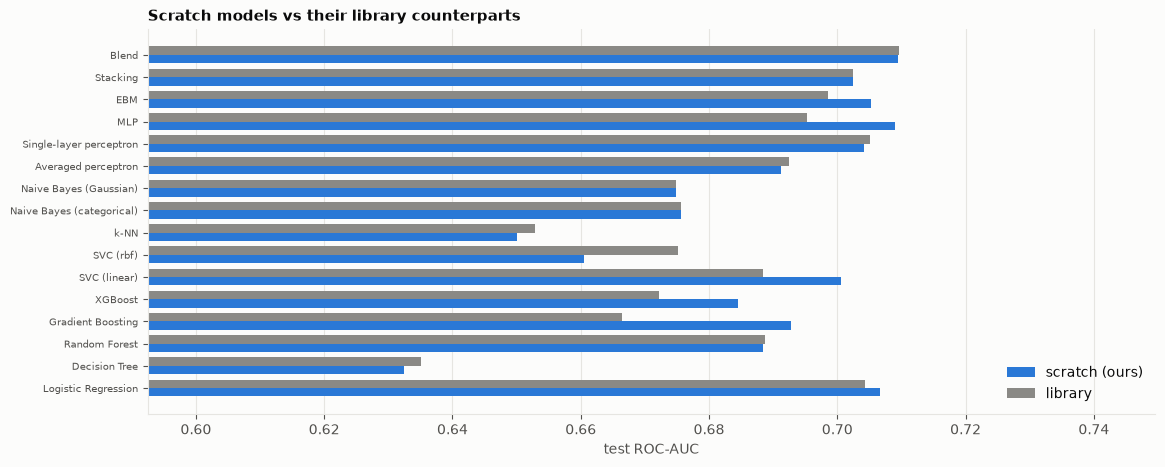

In [5]:
import json

checks = []
for n in FOLDERS:
    with open(res(n, "check.json"), encoding="utf-8") as f:
        c = json.load(f)
    checks += c if isinstance(c, list) else [c]
vt = pd.DataFrame(checks).set_index("check")
vt.to_csv(out.table("scratch_vs_sklearn.csv"))
print(vt[["AUC scratch", "AUC sklearn", "difference", "the difference is"]].round(4).to_string())
pairs = vt.dropna(subset=["AUC scratch", "AUC sklearn"])
fig, ax = plt.subplots(figsize=(13, 5))
xs = np.arange(len(pairs))
ax.barh(xs - 0.19, pairs["AUC scratch"], 0.38, label="scratch (ours)", color=plots.BLUE)
ax.barh(xs + 0.19, pairs["AUC sklearn"], 0.38, label="library", color=plots.NEUTRAL)
ax.set_yticks(xs, [c.split(" vs ")[0] for c in pairs.index], fontsize=7.5)
ax.set_xlim(
    max(0.4, pairs[["AUC scratch", "AUC sklearn"]].min().min() - 0.04),
    min(1.0, pairs[["AUC scratch", "AUC sklearn"]].max().max() + 0.04),
)
ax.grid(axis="y", visible=False)
ax.set_xlabel("test ROC-AUC")
ax.set_title("Scratch models vs their library counterparts")
ax.legend(loc="lower right")
plots._save(fig, out.image("scratch_vs_sklearn.png"))

## Feature importance: แต่ละโมเดลเห็นตรงกันไหม

importance tables from: Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, XGBoost, SVC (linear), SVC (rbf), k-NN, Naive Bayes, Perceptron (averaged), Single-Layer Perceptron, MLP, EBM (additive)


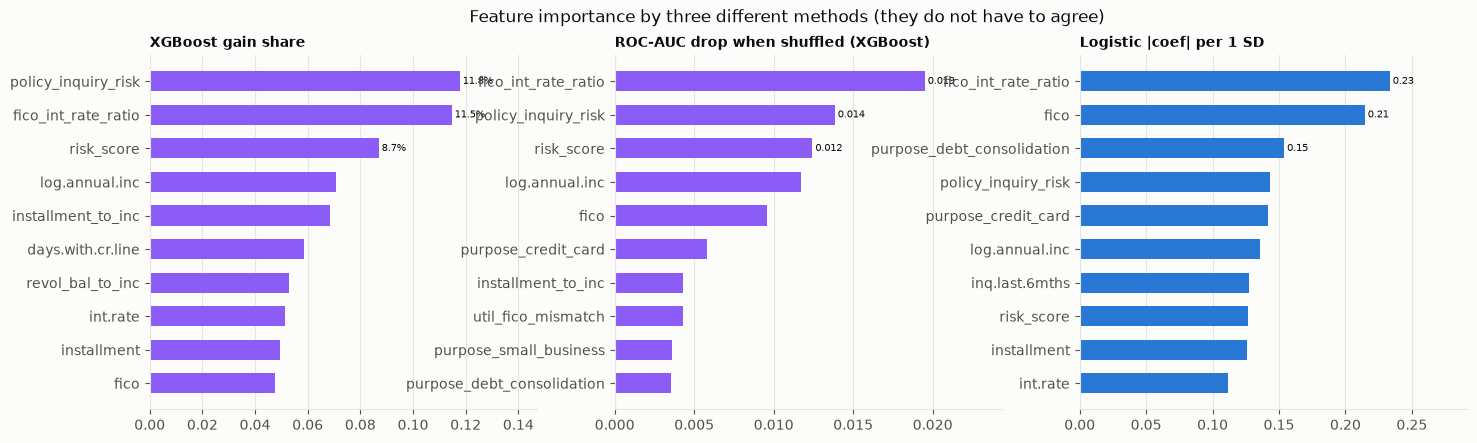

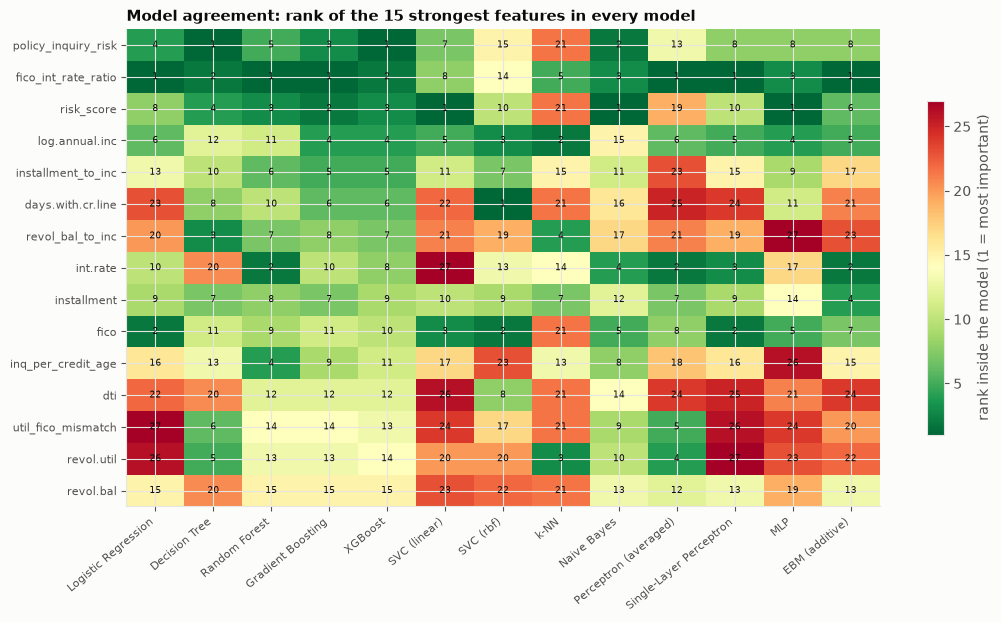

In [6]:
imp = pd.DataFrame(
    {
        n: pd.read_csv(res(n, "feature_importance.csv"), index_col=0)["importance_share"]
        for n in FOLDERS
        if os.path.exists(res(n, "feature_importance.csv"))
    }
)
perm = pd.read_csv(res("XGBoost", "permutation_importance.csv"), index_col=0)["roc_auc_drop"]
coefs = pd.read_csv(res("Logistic Regression", "coefficients.csv"), index_col=0)
imp_all = (
    imp.join(perm.rename("xgboost_permutation_aucloss"))
    .join(coefs[["coef_per_1SD", "odds_ratio"]].add_prefix("logistic_"))
    .sort_values("XGBoost", ascending=False)
)
imp_all.to_csv(out.table("feature_importance.csv"), index_label="feature")
print(f"importance tables from: {', '.join(imp.columns)}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, s, title, col, fmt in (
    (axes[0], imp["XGBoost"], "XGBoost gain share", COLORS["XGBoost"], "{:.1%}"),
    (axes[1], perm, "ROC-AUC drop when shuffled (XGBoost)", COLORS["XGBoost"], "{:.3f}"),
    (axes[2], coefs["coef_per_1SD"].abs(), "Logistic |coef| per 1 SD", COLORS["Logistic Regression"], "{:.2f}"),
):
    s = s.sort_values(ascending=False).head(10)[::-1]
    ax.barh(s.index, s.values, color=col, height=0.6)
    for name, v in list(s.items())[-3:]:
        ax.text(v, name, " " + fmt.format(v), va="center", fontsize=7)
    ax.set_xlim(0, s.max() * 1.25)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", visible=False)
fig.suptitle("Feature importance by three different methods (they do not have to agree)")
plots._save(fig, out.image("feature_importance.png"))

hot = imp["XGBoost"].sort_values(ascending=False).head(15).index
ranks = pd.DataFrame({n: imp[n].rank(ascending=False).reindex(hot) for n in imp.columns})
fig, ax = plt.subplots(figsize=(0.55 * len(imp.columns) + 5, 6.2))
im = ax.imshow(ranks.values, cmap="RdYlGn_r", aspect="auto")
ax.set_xticks(range(len(imp.columns)), list(imp.columns), rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(hot)), hot, fontsize=8)
for (i, j), v in np.ndenumerate(ranks.values):
    ax.text(j, i, int(v), ha="center", va="center", fontsize=6.5)
fig.colorbar(im, ax=ax, shrink=0.7, label="rank inside the model (1 = most important)")
ax.set_title("Model agreement: rank of the 15 strongest features in every model")
plots._save(fig, out.image("feature_importance_agreement.png"))

## 5-fold cross-validation
เทรนใหม่ทุกโมเดล 5 รอบ (20% ของ train ในแต่ละ fold เป็น validation) ใช้เวลานาน

  fold 1/5 done


  fold 2/5 done


  fold 3/5 done


  fold 4/5 done


  fold 5/5 done


                              CV ROC-AUC mean  CV ROC-AUC std  CV PR-AUC mean  CV PR-AUC std  CV recall@f1.5 mean  CV recall@f1.5 std
Blend EBM+MLP (better model)         0.682194        0.019098        0.285998       0.013867             0.750857            0.074737
MLP                                  0.681904        0.019324        0.285076       0.013885             0.732609            0.090310
EBM (additive)                       0.678344        0.017253        0.283565       0.013492             0.743056            0.117242
Single-Layer Perceptron              0.677366        0.017681        0.283406       0.012755             0.722122            0.092320
Logistic Regression                  0.677233        0.016749        0.282717       0.013677             0.743033            0.110398
Stacking (5 bases)                   0.677110        0.019305        0.279989       0.015493             0.729314            0.054102
SVC (linear)                         0.674921        0.019090 

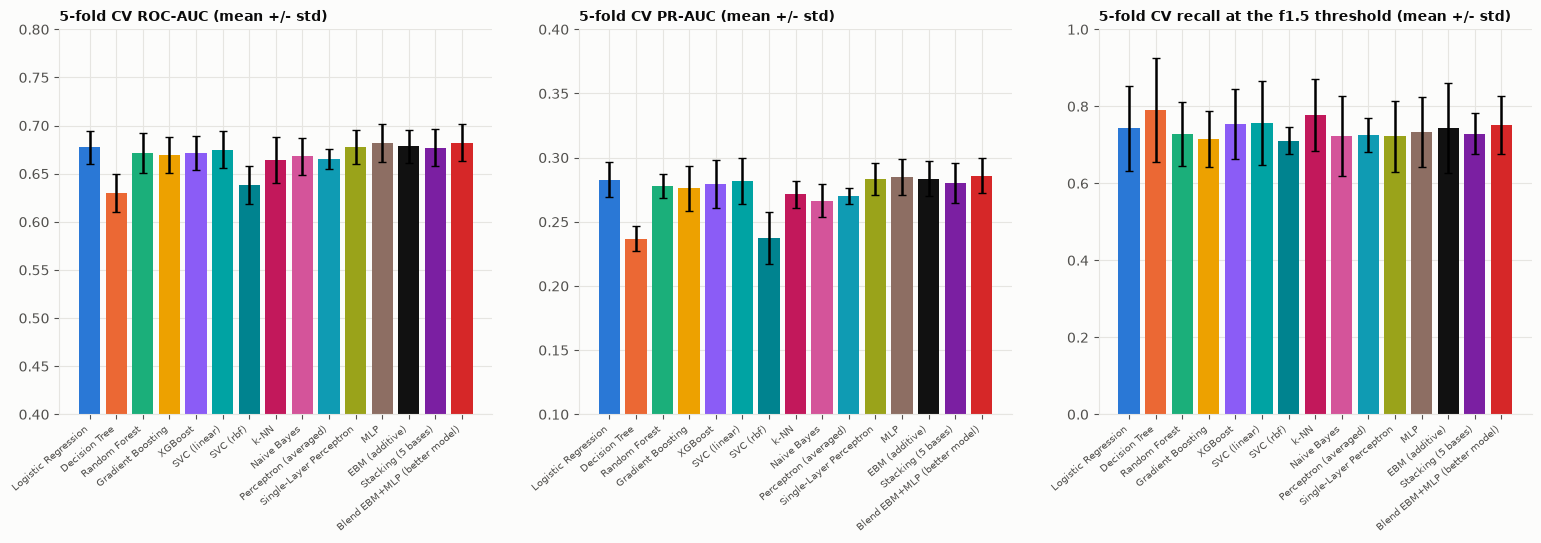

In [7]:
CV_FOLDS = 5
folds = stratified_folds(d.y, CV_FOLDS, SEED)
cv_scores = {n: {"roc": [], "pr": [], "rec": []} for n in models}
for k, (tr, te) in enumerate(folds, 1):
    cut = int(len(tr) * 0.8)
    rk = np.random.RandomState(SEED + k)
    pos, neg = tr[d.y[tr] == 1], tr[d.y[tr] == 0]
    rk.shuffle(pos)
    rk.shuffle(neg)
    n_va = len(tr) - cut
    n_pos_va = max(1, int(round(n_va * len(pos) / len(tr))))
    va_idx = np.concatenate([pos[:n_pos_va], neg[: n_va - n_pos_va]])
    tr_idx = np.setdiff1d(tr, va_idx)
    for n, (make, use_val) in models.items():
        m = fit_model(make(), use_val, d.X[tr_idx], d.y[tr_idx], d.X[va_idx], d.y[va_idx], d.feature_cols)
        p = m.predict_proba(d.X[te])[:, 1]
        thr, _ = choose_threshold(
            d.y[va_idx], m.predict_proba(d.X[va_idx])[:, 1], rule=FLAG_RULE, base_rate=float(d.y[va_idx].mean())
        )
        cv_scores[n]["roc"].append(roc_auc(d.y[te], p))
        cv_scores[n]["pr"].append(average_precision(d.y[te], p))
        cv_scores[n]["rec"].append(recall(d.y[te], p, thr))
    print(f"  fold {k}/{CV_FOLDS} done", flush=True)
cv = pd.DataFrame(
    {
        n: {
            "CV ROC-AUC mean": np.mean(v["roc"]),
            "CV ROC-AUC std": np.std(v["roc"]),
            "CV PR-AUC mean": np.mean(v["pr"]),
            "CV PR-AUC std": np.std(v["pr"]),
            f"CV recall@{FLAG_RULE} mean": np.mean(v["rec"]),
            f"CV recall@{FLAG_RULE} std": np.std(v["rec"]),
        }
        for n, v in cv_scores.items()
    }
).T
cv.to_csv(out.table("cv_summary.csv"), index_label="Model")
pd.DataFrame(
    {f"{n} {k}": v[k] for n, v in cv_scores.items() for k in ("roc", "pr", "rec")},
    index=[f"fold {k}" for k in range(1, CV_FOLDS + 1)],
).to_csv(out.table("cv_folds.csv"), index_label="fold")
print(cv.sort_values("CV ROC-AUC mean", ascending=False).to_string())

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, key, title, ylim in (
    (axes[0], "roc", "ROC-AUC", (0.4, 0.8)),
    (axes[1], "pr", "PR-AUC", (0.1, 0.4)),
    (axes[2], "rec", f"recall at the {FLAG_RULE} threshold", (0.0, 1.0)),
):
    ax.bar(
        list(cv_scores),
        [np.mean(cv_scores[n][key]) for n in cv_scores],
        yerr=[np.std(cv_scores[n][key]) for n in cv_scores],
        color=[COLORS[n] for n in cv_scores],
        capsize=3,
    )
    ax.set_ylim(*ylim)
    ax.set_title(f"{CV_FOLDS}-fold CV {title} (mean +/- std)", fontsize=10)
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right", fontsize=7.5)
plots._save(fig, out.image("cv_scores.png"))

## Batch runs: สุ่มแบ่ง 60/20/20 ใหม่ 10 รอบ

  split 1/10 done in 152s


  split 2/10 done in 150s


  split 3/10 done in 152s


  split 4/10 done in 161s


  split 5/10 done in 177s


...

  split 7/10 done in 175s


  split 8/10 done in 159s


  split 9/10 done in 164s


  split 10/10 done in 162s


                              ROC-AUC mean  ROC-AUC SD  PR-AUC mean  PR-AUC SD  recall@f1.5 mean  recall@f1.5 SD  accuracy@0.5 mean
Blend EBM+MLP (better model)      0.676644    0.014245     0.288749   0.014254          0.772794        0.089736           0.818476
MLP                               0.675513    0.014963     0.286927   0.012686          0.765688        0.106315           0.817067
EBM (additive)                    0.674278    0.013252     0.289793   0.013104          0.797876        0.057686           0.817119
Logistic Regression               0.673679    0.013354     0.289675   0.013025          0.782081        0.075304           0.816754
Single-Layer Perceptron           0.673584    0.013200     0.288919   0.013674          0.770516        0.085331           0.816649
Stacking (5 bases)                0.673065    0.013635     0.287733   0.009815          0.792058        0.054312           0.838361
SVC (linear)                      0.670791    0.012385     0.288399   0.0162

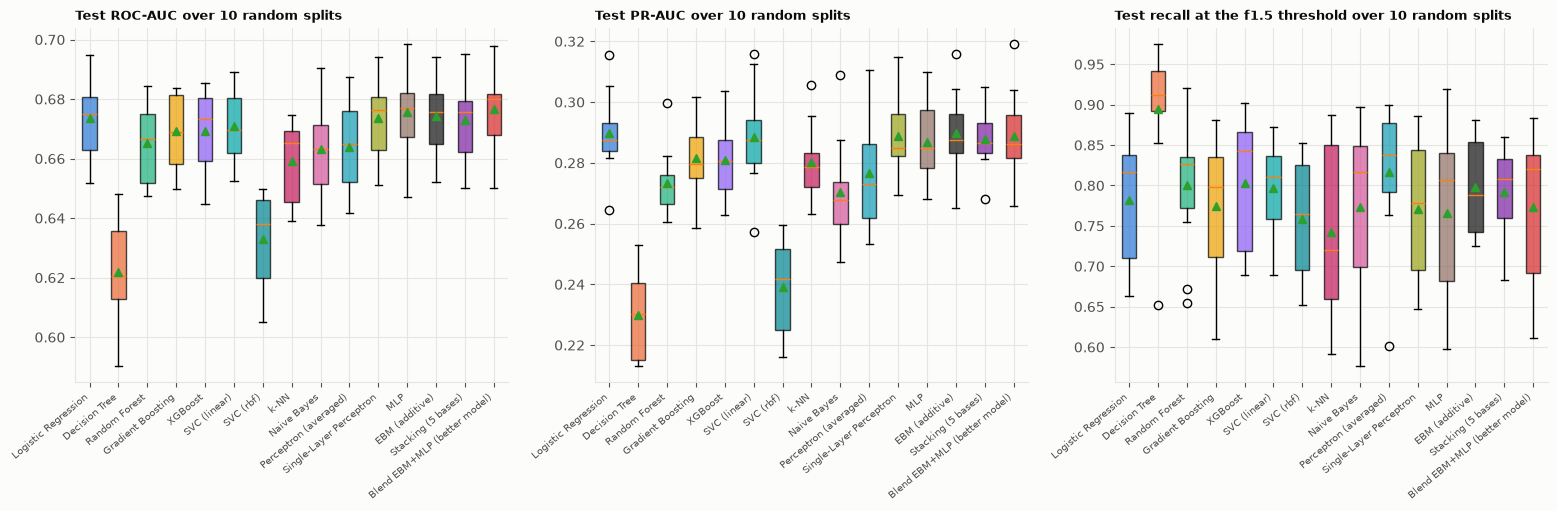

In [8]:
N_BATCH = 10
bres = {n: {"auc": [], "pr": [], "rec": [], "acc": []} for n in models}
for b in range(N_BATCH):
    t0 = time.time()
    s_tr, s_va, s_te, t_tr, t_va, t_te = train_val_test_split_scratch(d.X, d.y, seed=500 + b)
    for n, (make, use_val) in models.items():
        m = fit_model(make(), use_val, s_tr, t_tr, s_va, t_va, d.feature_cols)
        p = m.predict_proba(s_te)[:, 1]
        thr, _ = choose_threshold(t_va, m.predict_proba(s_va)[:, 1], rule=FLAG_RULE, base_rate=float(t_va.mean()))
        bres[n]["auc"].append(roc_auc(t_te, p))
        bres[n]["pr"].append(average_precision(t_te, p))
        bres[n]["rec"].append(recall(t_te, p, thr))
        bres[n]["acc"].append(float(((p >= 0.5).astype(int) == t_te).mean()))
    print(f"  split {b + 1}/{N_BATCH} done in {time.time() - t0:.0f}s", flush=True)
bt = pd.DataFrame(
    {
        n: {
            "ROC-AUC mean": np.mean(v["auc"]),
            "ROC-AUC SD": np.std(v["auc"]),
            "PR-AUC mean": np.mean(v["pr"]),
            "PR-AUC SD": np.std(v["pr"]),
            f"recall@{FLAG_RULE} mean": np.mean(v["rec"]),
            f"recall@{FLAG_RULE} SD": np.std(v["rec"]),
            "accuracy@0.5 mean": np.mean(v["acc"]),
        }
        for n, v in bres.items()
    }
).T
bt.to_csv(out.table("batch_runs.csv"), index_label="Model")
rank = bt["ROC-AUC mean"].sort_values(ascending=False)
print(bt.loc[rank.index].to_string())
for n in rank.index[1:6]:
    dlt = np.array(bres[n]["auc"]) - np.array(bres[rank.index[0]]["auc"])
    print(
        f"  {n:<26} minus {rank.index[0]}: {dlt.mean():+.4f} AUC (SD {dlt.std():.4f}), better in {(dlt > 0).sum()}/{N_BATCH} splits"
    )

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
for ax, k, t in (
    (axes[0], "auc", "ROC-AUC"),
    (axes[1], "pr", "PR-AUC"),
    (axes[2], "rec", f"recall at the {FLAG_RULE} threshold"),
):
    bp = ax.boxplot([bres[n][k] for n in bres], tick_labels=list(bres), patch_artist=True, showmeans=True)
    for patch, n in zip(bp["boxes"], bres):
        patch.set_facecolor(COLORS[n])
        patch.set_alpha(0.7)
    ax.set_title(f"Test {t} over {N_BATCH} random splits", fontsize=9)
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right", fontsize=7.5)
plots._save(fig, out.image("batch_runs.png"))

## ตารางสรุป

In [9]:
table = bench.join(cv).join(bt.add_prefix("batch "))
taught = ["Logistic Regression", "Decision Tree", "Random Forest", "Gradient Boosting", "XGBoost"]
table["ROC-AUC gain vs best taught model"] = table["test_roc_auc"] - table.loc[taught, "test_roc_auc"].max()
table["PR-AUC gain vs random"] = table["test_pr_auc"] - y_te.mean()
table.to_csv(out.table("benchmark_with_cv.csv"), index_label="Model")
view = table[
    [
        "test_roc_auc",
        "test_pr_auc",
        "test_recall",
        "test_fn",
        "CV ROC-AUC mean",
        "batch ROC-AUC mean",
        "batch ROC-AUC SD",
    ]
]
print(view.sort_values("test_roc_auc", ascending=False).round(4).to_string())

best_roc = bench["test_roc_auc"].idxmax()
best_recall = bench["test_recall"].idxmax()
print(f"\ndata          : {len(d.y):,} borrowers, {len(d.feature_cols)} features, {d.y.mean():.1%} defaulters")
print(
    f"accuracy trap : answering 'everybody pays' scores {1 - y_te.mean():.1%} accuracy, so use ROC-AUC / PR-AUC / recall"
)
print(
    f"best ranking  : {best_roc} ROC-AUC {bench.loc[best_roc, 'test_roc_auc']:.4f} | PR-AUC {bench.loc[best_roc, 'test_pr_auc']:.4f}"
)
print(
    f"most caught   : {best_recall} catches {bench.loc[best_recall, 'test_recall']:.1%} (misses {int(bench.loc[best_recall, 'test_fn'])} of {int(y_te.sum())})"
)
print(
    f"better model  : ROC-AUC {bench.loc[BETTER, 'test_roc_auc']:.4f} | EBM {blend['ebm_weight']:.2f} + MLP bag {1 - blend['ebm_weight']:.2f}"
)
print(
    f"flagging rule : {FLAG_RULE} flags {rules['flagged'].mean():.1%} of applicants on average and catches {rules['recall'].mean():.1%} of defaulters"
)

                              test_roc_auc  test_pr_auc  test_recall  test_fn  CV ROC-AUC mean  batch ROC-AUC mean  batch ROC-AUC SD
Model                                                                                                                               
Blend EBM+MLP (better model)        0.7095       0.2973       0.9148       26           0.6822              0.6766            0.0142
MLP                                 0.7089       0.2967       0.9115       27           0.6819              0.6755            0.0150
Logistic Regression                 0.7067       0.2966       0.8623       42           0.6772              0.6737            0.0134
EBM (additive)                      0.7053       0.2955       0.8689       40           0.6783              0.6743            0.0133
Single-Layer Perceptron             0.7050       0.2970       0.8656       41           0.6774              0.6736            0.0132
Stacking (5 bases)                  0.7025       0.2944       0.8623 